## 1. Imports, configuration and helpers

In [2]:
import io, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler, FunctionTransformer, label_binarize
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import f_classif, mutual_info_classif, SelectKBest
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             precision_score, recall_score, roc_auc_score,
                             confusion_matrix, classification_report)

# Warnings are intentionally NOT globally silenced, so genuine issues
# (e.g. non-convergence) remain visible.

RANDOM_STATE = 42
sns.set_style("whitegrid")
%matplotlib inline
np.random.seed(RANDOM_STATE)

# Final models (reported). A lighter forest is used ONLY inside CV/tuning loops for speed;
# this is stated wherever it is used.
def make_lr():       return LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
def make_rf():       return RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                   class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)
def make_rf_light(): return RandomForestClassifier(n_estimators=80, min_samples_leaf=2,
                                                   class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE)

CV5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
CV3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

def multiclass_scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Macro-Prec": precision_score(y_true, y_pred, average="macro"),
            "Macro-Recall": recall_score(y_true, y_pred, average="macro"),
            "Macro-F1": f1_score(y_true, y_pred, average="macro"),
            "Balanced-Acc": balanced_accuracy_score(y_true, y_pred)}

## 2. Load the dataset from the original UCI `.dat` files

Canonical source: **UCI ML Repository, ID 270**
(`https://archive.ics.uci.edu/dataset/270/gas+sensor+array+drift+at+different+concentrations`).

The dataset ships as ten files, `batch1.dat … batch10.dat`, one per acquisition period, in a
sparse `class;concentration index:value …` format. **Taking the batch number from the filename
guarantees the correct chronological order** — important for the drift study, and more reliable
than a pre-flattened CSV whose batch column could be re-ordered. We download and parse them
below (if the files are already in `./data/`, those are used instead). The `.dat` files are fetched from a public **GitHub mirror** of the UCI files; the canonical source remains UCI ID 270.

Numeric class labels map to gases per the UCI documentation
(1=Ethanol, 2=Ethylene, 3=Ammonia, 4=Acetaldehyde, 5=Acetone, 6=Toluene).

In [3]:
GAS = {1:"Ethanol", 2:"Ethylene", 3:"Ammonia", 4:"Acetaldehyde", 5:"Acetone", 6:"Toluene"}
BASE = "https://raw.githubusercontent.com/HakanKARASU/Gas-Sensor-Array-Drift-Dataset/main/"
FEATURES = [f"feature_{i}" for i in range(1, 129)]

def parse_dat(lines):
    labels, concs, feats = [], [], []
    for line in lines:
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        cls, conc = parts[0].split(";")            # 'class;concentration'
        row = np.zeros(128)
        for tok in parts[1:]:
            idx, val = tok.split(":")
            row[int(idx)-1] = float(val)
        labels.append(int(cls)); concs.append(float(conc)); feats.append(row)
    return np.array(feats), np.array(labels), np.array(concs)

def load_batch(b):
    local = Path("data")/f"batch{b}.dat"
    if local.exists():
        with open(local) as f: lines = f.readlines()
    else:
        lines = urllib.request.urlopen(BASE + f"batch{b}.dat").read().decode().splitlines()
    X, y, conc = parse_dat(lines)
    dfb = pd.DataFrame(X, columns=FEATURES)
    dfb["gas"] = [GAS[c] for c in y]
    dfb["batch"] = b                                # true chronological batch from filename
    dfb["concentration"] = conc                     # METADATA only - never used as a predictor
    return dfb

df = pd.concat([load_batch(b) for b in range(1, 11)], ignore_index=True)
print("Loaded shape:", df.shape)
df.head(3)

Loaded shape: (13910, 131)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_122,feature_123,feature_124,feature_125,feature_126,feature_127,feature_128,gas,batch,concentration
0,15596.1621,1.868245,2.371604,2.803678,7.512213,-2.739388,-3.344671,-4.847512,15326.6914,1.768526,...,3.972203,0.527291,0.728443,1.445783,-0.545079,-0.902241,-2.654529,Ethanol,1,10.0
1,26402.0704,2.532401,5.411209,6.509906,7.658469,-4.722217,-5.817651,-7.518333,23855.7812,2.164706,...,4.281373,0.980205,1.628050,1.951172,-0.889333,-1.323505,-1.749225,Ethanol,1,20.0
2,42103.5820,3.454189,8.198175,10.508439,11.611003,-7.668313,-9.478675,-12.230939,37562.3008,2.840403,...,5.396827,1.403973,2.476956,3.039841,-1.334558,-1.993659,-2.348370,Ethanol,1,30.0


In [4]:
# Validate against the documented UCI ten-batch counts (total 13,910)
expected = {1:445, 2:1244, 3:1586, 4:161, 5:197, 6:2300, 7:3613, 8:294, 9:470, 10:3600}
counts = df["batch"].value_counts().sort_index().to_dict()
print("Per-batch counts match UCI documentation:", counts == expected)
print("Total rows:", len(df), "| Missing values:", int(df[FEATURES].isna().sum().sum()))

Per-batch counts match UCI documentation: True
Total rows: 13910 | Missing values: 0


## 3. Dataset description and audit

Recorded at UC San Diego over **36 months (2008–2011)** with **16 metal-oxide sensors**, each
summarised by **8 features → 128 features**. 13,910 measurements, 6 gases, 10 time batches.
Licence CC BY 4.0.

*Citation: Vergara, A. et al. (2012). Gas Sensor Array Drift Dataset at Different
Concentrations. UCI ML Repository. https://doi.org/10.24432/C5MK6M*

A key audit for the drift study is the **class-by-batch table** — we must check every gas is
present in both the early and later periods, or a chronological split could become unlearnable.

In [5]:
print("Gas class counts:\n", df["gas"].value_counts(), "\n")
print("Feature scale (min .. max): {:.0f} .. {:.0f}".format(df[FEATURES].values.min(), df[FEATURES].values.max()))
print("Most skewed features:\n", df[FEATURES].skew().abs().sort_values(ascending=False).head(3).round(1), "\n")
print("Class-by-batch (chronological):")
pd.crosstab(df["batch"], df["gas"])

Gas class counts:
 gas
Acetone         3009
Ethylene        2926
Ethanol         2565
Acetaldehyde    1936
Toluene         1833
Ammonia         1641
Name: count, dtype: int64 

Feature scale (min .. max): -23661 .. 670687
Most skewed features:
 feature_42    117.9
feature_58    117.8
feature_50    117.3
dtype: float64 

Class-by-batch (chronological):


gas,Acetaldehyde,Acetone,Ammonia,Ethanol,Ethylene,Toluene
batch,,,,,,
1,30,70,83,90,98,74
2,109,532,100,164,334,5
3,240,275,216,365,490,0
4,30,12,12,64,43,0
5,46,63,20,28,40,0
6,29,606,110,514,574,467
7,744,630,360,649,662,568
8,33,143,40,30,30,18
9,75,78,100,61,55,101


> **Audit notes.** No missing values; mild class imbalance (so macro-averaged metrics are
> preferred); features span ~6 orders of magnitude with heavy skew (→ standardisation is
> essential). All six gases appear across the early and late batches, so a chronological split
> remains a valid six-class problem. Batch sizes are very uneven, which matters when averaging
> per-batch scores later.

## 4. Exploratory data analysis

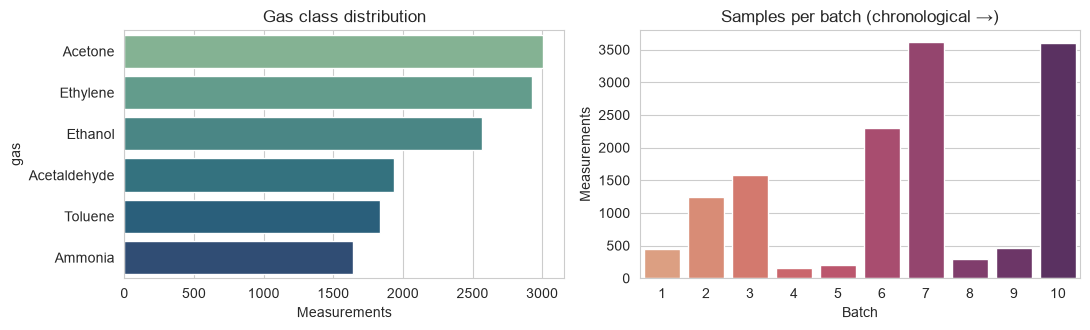

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
vc = df["gas"].value_counts()
sns.barplot(x=vc.values, y=vc.index, hue=vc.index, palette="crest", legend=False, ax=ax[0])
ax[0].set_title("Gas class distribution"); ax[0].set_xlabel("Measurements")
bs = df["batch"].value_counts().sort_index()
sns.barplot(x=bs.index.astype(str), y=bs.values, hue=bs.index.astype(str), palette="flare", legend=False, ax=ax[1])
ax[1].set_title("Samples per batch (chronological \u2192)"); ax[1].set_xlabel("Batch"); ax[1].set_ylabel("Measurements")
plt.tight_layout(); plt.show()

### 4.1 Gas-class composition across batches (Figure B)

The drift study trains on early batches and tests on later ones, so we must know whether the
*class mix itself* changes over time — otherwise an accuracy drop could be blamed on drift when it
is really a composition change. The 100%-stacked bar makes any shift visible.

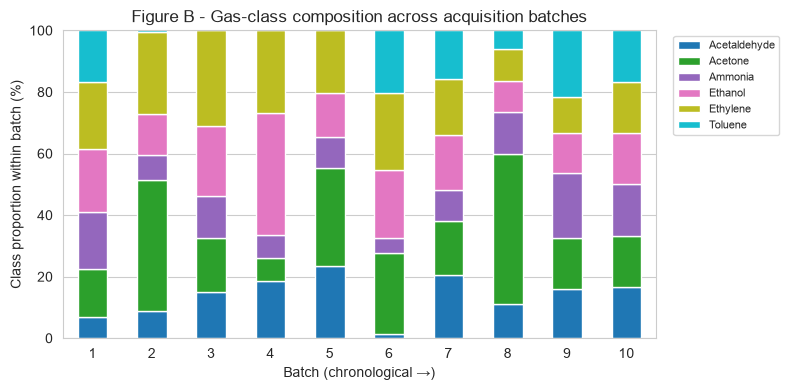

In [7]:
comp = (pd.crosstab(df["batch"], df["gas"], normalize="index") * 100)
comp = comp[sorted(comp.columns)]
comp.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="tab10")
plt.ylabel("Class proportion within batch (%)"); plt.xlabel("Batch (chronological \u2192)")
plt.title("Figure B - Gas-class composition across acquisition batches")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

### 4.2 Concentration as a confounder (metadata, not a feature)

Each measurement has a gas **concentration** (ppmv, per the UCI documentation). We keep it only as
*metadata* — it is **never** a model input (`X = df[FEATURES]` uses the 128 sensor features alone).
If concentration distributions differ across batches, an accuracy drop on later batches could be
partly a concentration effect rather than pure sensor drift — important context for the drift study.

Median concentration (ppmv) by batch:
batch
1     125.0
2     175.0
3     150.0
4     100.0
5     200.0
6      50.0
7     110.0
8     100.0
9     100.0
10    150.0


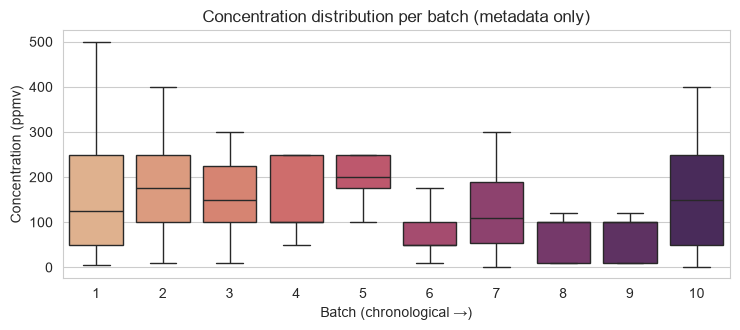

In [8]:
print("Median concentration (ppmv) by batch:")
print(df.groupby("batch")["concentration"].median().round(1).to_string())
plt.figure(figsize=(7.5, 3.4))
sns.boxplot(data=df, x="batch", y="concentration", hue="batch", palette="flare", legend=False, showfliers=False)
plt.title("Concentration distribution per batch (metadata only)")
plt.xlabel("Batch (chronological \u2192)"); plt.ylabel("Concentration (ppmv)")
plt.tight_layout(); plt.show()

## 5. Train/test split

A **stratified 75/25 split** for the random-split protocol. Everything learned from data is fit
on the training part only; the test part is untouched until the final evaluation (Section 14).

In [9]:
X = df[FEATURES].copy()
y = df["gas"].values
batch = df["batch"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (10432, 128)  Test: (3478, 128)


### 5.0 Feature redundancy — correlation heatmap (Figure A)

Many sensor-response features are strongly correlated, which is what motivates both correlation-aware
feature selection and PCA. We show a readable subset (the first three sensors = 24 features),
computed on the **training set** so nothing is learned from held-out data.

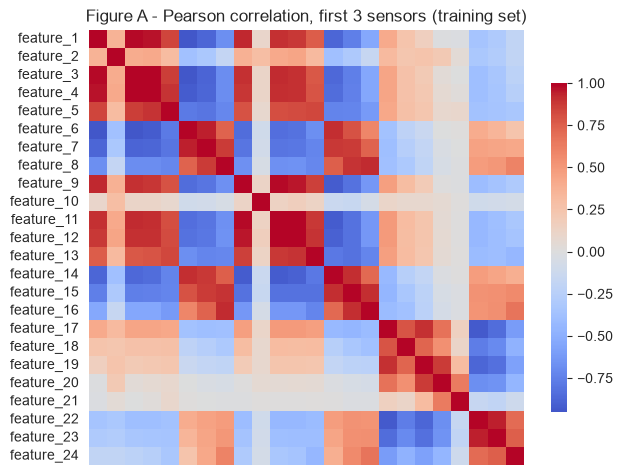

In [10]:
subset = [f"feature_{i}" for i in range(1, 25)]   # first 3 sensors x 8 features
plt.figure(figsize=(6.5, 5.2))
sns.heatmap(X_train[subset].corr(), cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": .7}, xticklabels=False)
plt.title("Figure A - Pearson correlation, first 3 sensors (training set)")
plt.tight_layout(); plt.show()

### 5.1 Does standardisation help? (training-only cross-validation)

We compare Logistic Regression with and without scaling using **CV on the training set** (not the
test set), so this is a fair, leakage-free check and the first step in *how accuracy is obtained*. The unscaled model may emit convergence warnings — that is itself evidence that unscaled, six-orders-of-magnitude features hinder the optimiser; its accuracy is not that of a fully converged model.

In [11]:
lr_noscale = Pipeline([("model", make_lr())])
lr_scaled  = Pipeline([("scale", StandardScaler()), ("model", make_lr())])
s0 = cross_val_score(lr_noscale, X_train, y_train, cv=CV3, scoring="accuracy", n_jobs=-1)
s1 = cross_val_score(lr_scaled,  X_train, y_train, cv=CV3, scoring="accuracy", n_jobs=-1)
print(f"LR CV accuracy WITHOUT scaling : {s0.mean():.4f} +/- {s0.std():.4f}")
print(f"LR CV accuracy WITH scaling    : {s1.mean():.4f} +/- {s1.std():.4f}")
print(f"Improvement from standardisation: {s1.mean()-s0.mean():+.4f}")

LR CV accuracy WITHOUT scaling : 0.9780 +/- 0.0013
LR CV accuracy WITH scaling    : 0.9885 +/- 0.0011
Improvement from standardisation: +0.0105


## 6. Feature engineering 
Feature engineering *creates* new, potentially more informative inputs. The 128 features are
laid out as **16 sensors × 8 features**. We add three principled groups:

1. **Signed-log transform** of every raw feature - tames the six-order-of-magnitude skew while
   preserving sign: `sign(x)·log(1+|x|)`.
2. **Per-sensor aggregates** - each sensor's mean and range across its 8 features (32 features),
   summarising each physical sensor's behaviour.
3. **Cross-sensor ratios** - each sensor-mean divided by the array-wide mean (16 features).
   Ratios cancel overall magnitude, which **drifts over time**, so they are a deliberately
   *drift-robust* representation - a direct link to the drift study later.

All three are **row-wise** (no information crosses between rows), so they introduce no leakage.

In [10]:
def engineer(frame):
    v = frame[FEATURES].values
    out = {}
    # 1. signed-log of each raw feature
    slog = np.sign(v) * np.log1p(np.abs(v))
    for i in range(128): out[f"slog_{i+1}"] = slog[:, i]
    # 2. per-sensor aggregates (16 sensors x 8 features)
    sensor_means = np.zeros((v.shape[0], 16))
    for s in range(16):
        block = v[:, s*8:(s+1)*8]
        sensor_means[:, s] = block.mean(axis=1)
        out[f"sensor{s+1}_mean"]  = block.mean(axis=1)
        out[f"sensor{s+1}_range"] = block.max(axis=1) - block.min(axis=1)
    # 3. cross-sensor ratios (sensor mean / array-wide mean)
    array_mean = sensor_means.mean(axis=1, keepdims=True)
    array_mean[array_mean == 0] = 1e-9
    for s in range(16):
        out[f"sensor{s+1}_ratio"] = sensor_means[:, s] / array_mean[:, 0]
    return pd.DataFrame(out, index=frame.index)

X_train_eng = engineer(X_train)
X_test_eng  = engineer(X_test)
print("Engineered feature count:", X_train_eng.shape[1],
      "(128 signed-log + 32 aggregates + 16 ratios)")
X_train_eng.iloc[:3, [0, 128, 129, 160]]

Engineered feature count: 176 (128 signed-log + 32 aggregates + 16 ratios)


,slog_1,sensor1_mean,sensor1_range,sensor1_ratio
3947,11.644161,14247.024529,114093.558989,3.592248
1018,10.148637,3196.092151,25563.943674,2.798330
6796,10.736675,5753.155805,46048.681388,2.242191


## 7. Feature selection 

Feature selection *chooses* which features to keep, using three taught techniques:
**correlation redundancy**, the **ANOVA F-test** (`f_classif`), and **Mutual Information**
(`mutual_info_classif`). Chi-square is not used — it is for categorical features and ours are
all continuous. Everything is computed on the **training set only**, and we keep the Lab 02
caveat in mind: *statistical significance is not the same as predictive usefulness*.

In [11]:
# Standardise the engineered features (fit on train only)
eng_scaler = StandardScaler().fit(X_train_eng)
Xtr_eng_s = pd.DataFrame(eng_scaler.transform(X_train_eng), columns=X_train_eng.columns, index=X_train_eng.index)
Xte_eng_s = pd.DataFrame(eng_scaler.transform(X_test_eng),  columns=X_test_eng.columns,  index=X_test_eng.index)

# 7a. correlation redundancy: drop one of any pair with |r| > 0.95
corr = np.corrcoef(Xtr_eng_s.values, rowvar=False)
keep_idx, dropped = [], set()
for i in range(corr.shape[0]):
    if i in dropped: continue
    keep_idx.append(i)
    for j in range(i+1, corr.shape[0]):
        if j not in dropped and abs(corr[i, j]) > 0.95:
            dropped.add(j)
kept_cols = Xtr_eng_s.columns[keep_idx]
print(f"After correlation filter: {len(kept_cols)} of {Xtr_eng_s.shape[1]} features kept")

After correlation filter: 59 of 176 features kept


In [12]:
# 7b. ANOVA F-test and 7c. Mutual Information on the correlation-filtered features
Xtr_k = Xtr_eng_s[kept_cols].values
f_scores, _ = f_classif(Xtr_k, y_train)
# MI on a stratified subsample for speed (ranking is stable); documented choice
sub = np.random.RandomState(RANDOM_STATE).permutation(len(y_train))[:4000]
mi_scores = mutual_info_classif(Xtr_k[sub], y_train[sub], random_state=RANDOM_STATE)

rank = pd.DataFrame({"feature": kept_cols,
                     "ANOVA_F": f_scores,
                     "MutualInfo": mi_scores})
rank["anova_rank"] = rank["ANOVA_F"].rank(ascending=False)
rank["mi_rank"]    = rank["MutualInfo"].rank(ascending=False)
rank["avg_rank"]   = rank[["anova_rank", "mi_rank"]].mean(axis=1)
rank = rank.sort_values("avg_rank")
TOP_K = 40
selected_cols = rank.head(TOP_K)["feature"].tolist()
print(f"Selected top {TOP_K} features by average ANOVA+MI rank.\n")
display(rank.head(10).round(4))

Selected top 40 features by average ANOVA+MI rank.



,feature,ANOVA_F,MutualInfo,anova_rank,mi_rank,avg_rank
49,sensor2_ratio,4164.3786,0.9394,2.0,1.0,1.5
51,sensor4_ratio,10465.4036,0.8700,1.0,2.0,1.5
56,sensor13_ratio,2279.0422,0.7743,7.0,4.0,5.5
42,sensor2_mean,2549.4568,0.7052,5.0,8.0,6.5
50,sensor3_ratio,2023.8660,0.8381,10.0,3.0,6.5
28,slog_69,4055.0761,0.6711,3.0,13.0,8.0
55,sensor11_ratio,1493.1116,0.7605,13.0,5.0,9.0
7,slog_11,2898.1299,0.6028,4.0,18.0,11.0
53,sensor6_ratio,1458.5135,0.7165,16.0,7.0,11.5
26,slog_65,1414.3205,0.7176,18.0,6.0,12.0


## 8. Dimensionality reduction with PCA 

PCA re-expresses the standardised features as uncorrelated components ordered by variance.
We follow the Lab 11 workflow: explained-variance curve, a 95% cut, a 2-component view, and a
component sweep validated with cross-validation.

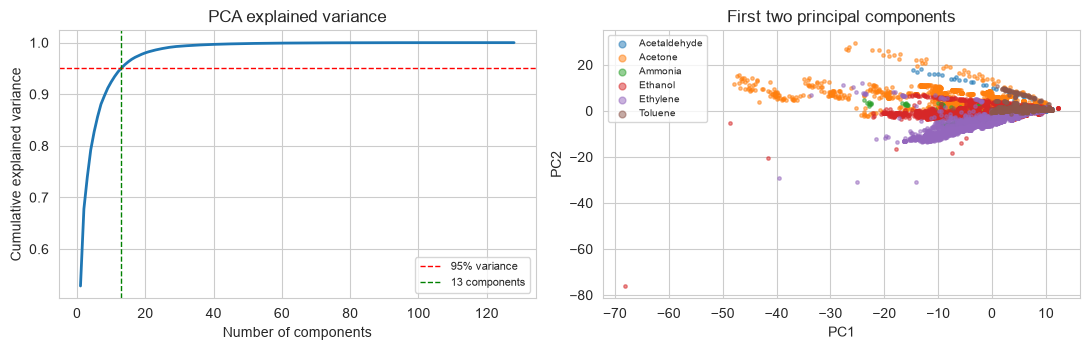

13 components capture 95% of the variance (from 128 features).


In [13]:
pca_full = PCA().fit(X_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(1, len(cum)+1), cum, lw=2)
ax[0].axhline(0.95, color="r", ls="--", lw=1, label="95% variance")
ax[0].axvline(n95, color="g", ls="--", lw=1, label=f"{n95} components")
ax[0].set_xlabel("Number of components"); ax[0].set_ylabel("Cumulative explained variance")
ax[0].set_title("PCA explained variance"); ax[0].legend(fontsize=8)

p2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_s)
for g in np.unique(y_train):
    m = y_train == g
    ax[1].scatter(p2[m, 0], p2[m, 1], s=6, alpha=.5, label=g)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("First two principal components")
ax[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()
print(f"{n95} components capture 95% of the variance (from 128 features).")

In [14]:
# Prepare the four feature representations (all fit on train only)
# 1. All standardised features
# 2. Engineered + selected features
# 3. PCA 95%
pca95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train_s)
Xtr_pca, Xte_pca = pca95.transform(X_train_s), pca95.transform(X_test_s)

representations = {
    "All (128)":        (X_train_s,                       X_test_s),
    "Engineered+Select":(Xtr_eng_s[selected_cols].values, Xte_eng_s[selected_cols].values),
    "PCA-95%":          (Xtr_pca,                         Xte_pca),
}
for k, (a, _) in representations.items():
    print(f"{k:20s}: {a.shape[1]} features")

All (128)           : 128 features
Engineered+Select   : 40 features
PCA-95%             : 13 features


## 9. Why these two algorithms? - a six-model screen

Before committing, we screen six classical algorithms (Labs 05–09) on the PCA features and
use the result to **justify** the choice. Only two are carried forward as the headline pair.

In [15]:
screen = {
    "Logistic Regression": make_lr(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Decision Tree":       DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       make_rf(),
    "Gaussian Naive Bayes":GaussianNB(),
    "SVM (RBF)":           SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
}
rows = []
for name, m in screen.items():
    t = time.time(); m.fit(Xtr_pca, y_train); dt = time.time() - t
    pred = m.predict(Xte_pca)
    rows.append({"Algorithm": name,
                 "Accuracy": round(accuracy_score(y_test, pred), 4),
                 "Macro-F1": round(f1_score(y_test, pred, average="macro"), 4),
                 "Train (s)": round(dt, 2)})
pd.DataFrame(rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

,Algorithm,Accuracy,Macro-F1,Train (s)
0,Random Forest,0.9925,0.9922,2.51
1,K-Nearest Neighbors,0.9891,0.9884,0.04
2,Decision Tree,0.9704,0.9682,0.46
3,SVM (RBF),0.9537,0.9490,1.64
4,Logistic Regression,0.9255,0.9178,1.22
5,Gaussian Naive Bayes,0.6294,0.6351,0.02


> **Reading the screen and the decision.** Random Forest is the strongest model, so it is
> our first choice. Gaussian Naive Bayes is clearly weakest - its conditional-independence
> assumption is violated by the heavily correlated sensor features, a textbook failure mode.
> KNN scores well on this random split but is non-interpretable and, as the drift study will
> show, fragile when the distribution shifts; SVM is strong but slower and also opaque. We
> therefore keep **Random Forest** (best, non-linear, gives feature importances) and
> **Logistic Regression** (interpretable linear baseline, maximally *distinct* from RF, and
> providing a second interpretability lens through its coefficients). This pairing gives the
> richest compare-and-contrast while satisfying the "two distinct algorithms" requirement.

## 10. Algorithm background

**Logistic Regression (Member A).** Models each class's log-odds as a linear combination of
the inputs (softmax for multiclass), trained by maximising regularised log-likelihood.
Interpretable (per-class coefficients), fast, probabilistic; limited to linear boundaries.

**Random Forest (Member B).** An ensemble of decision trees, each grown on a bootstrap sample
with a random feature subset per split; votes are averaged (bagging) to cut variance. Captures
non-linear interactions and yields feature importances, at the cost of interpretability and
compute. Both use `class_weight` to respect the mild imbalance.

## 11. Comparing the two algorithms across feature representations

In [16]:
results = {}
for rep, (Xtr_r, Xte_r) in representations.items():
    for name, factory in [("Logistic Regression", make_lr), ("Random Forest", make_rf)]:
        m = factory().fit(Xtr_r, y_train)
        s = multiclass_scores(y_test, m.predict(Xte_r)); s["n_feat"] = Xtr_r.shape[1]
        results[(rep, name)] = s
res_df = pd.DataFrame(results).T[["n_feat","Accuracy","Macro-Prec","Macro-Recall","Macro-F1","Balanced-Acc"]]
display(res_df.round(4))

n_feat  Accuracy  Macro-Prec  \
All (128)         Logistic Regression   128.0    0.9899      0.9890   
                  Random Forest         128.0    0.9942      0.9938   
Engineered+Select Logistic Regression    40.0    0.9879      0.9869   
                  Random Forest          40.0    0.9934      0.9935   
PCA-95%           Logistic Regression    13.0    0.9255      0.9172   
                  Random Forest          13.0    0.9925      0.9924   

                                       Macro-Recall  Macro-F1  Balanced-Acc  
All (128)         Logistic Regression        0.9901    0.9895        0.9901  
                  Random Forest              0.9943    0.9941        0.9943  
Engineered+Select Logistic Regression        0.9879    0.9874        0.9879  
                  Random Forest              0.9935    0.9935        0.9935  
PCA-95%           Logistic Regression        0.9185    0.9178        0.9185  
                  Random Forest              0.9921    0.9922        0.9921

## 12. How many PCA components are really needed? 
Using the Lab 11 component list, we cross-validate accuracy (5-fold) for each component count.
The CV sweeps use a lighter forest for speed.

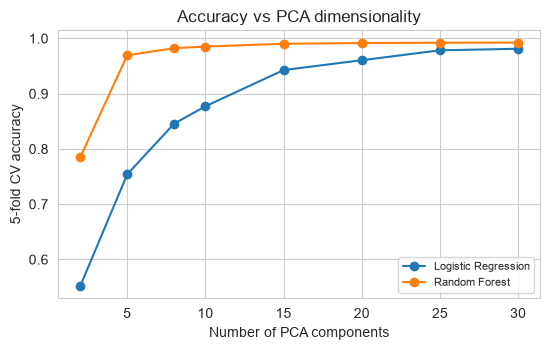

In [17]:
component_counts = [2, 5, 8, 10, 15, 20, 25, 30]
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
sweep = {"Logistic Regression": [], "Random Forest": []}
for n in component_counts:
    Xp = PCA(n_components=n, random_state=RANDOM_STATE).fit(X_train_s).transform(X_train_s)
    for name, factory in [("Logistic Regression", make_lr), ("Random Forest", make_rf_light)]:
        sc = cross_val_score(factory(), Xp, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
        sweep[name].append(sc.mean())
plt.figure(figsize=(5.6, 3.6))
for name in sweep: plt.plot(component_counts, sweep[name], marker="o", label=name)
plt.xlabel("Number of PCA components"); plt.ylabel("5-fold CV accuracy")
plt.title("Accuracy vs PCA dimensionality"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 13. Hyper-parameter tuning 

We tune both models on the PCA representation with 3-fold CV (macro-F1), then compare the
tuned models with their untuned baselines - the explicit *"how accuracy is obtained"* step.

In [18]:
grids = {
    "Logistic Regression": (make_lr(), {"C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (make_rf_light(), {"max_depth": [None, 20], "min_samples_leaf": [1, 2, 5]}),
}
cv3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
tune_rows = []
for name, (est, grid) in grids.items():
    base = est.fit(Xtr_pca, y_train)
    base_f1 = f1_score(y_test, base.predict(Xte_pca), average="macro")
    gs = GridSearchCV(est, grid, scoring="f1_macro", cv=cv3, n_jobs=-1).fit(Xtr_pca, y_train)
    tuned_f1 = f1_score(y_test, gs.predict(Xte_pca), average="macro")
    tune_rows.append({"Model": name, "Baseline Macro-F1": round(base_f1, 4),
                      "Tuned Macro-F1": round(tuned_f1, 4),
                      "Best params": str(gs.best_params_)})
pd.DataFrame(tune_rows)

,Model,Baseline Macro-F1,Tuned Macro-F1,Best params
0,Logistic Regression,0.9178,0.9226,{'C': 10}
1,Random Forest,0.9908,0.9932,"{'max_depth': 20, 'min_samples_leaf': 1}"


## 14. Learning curves - ruling out data scarcity

Before blaming drift for later failures, we check whether the models are simply starved of
data. If training and cross-validation curves have converged, more data would not help, so any
later degradation must come from **distribution shift (drift)**, not sample size.

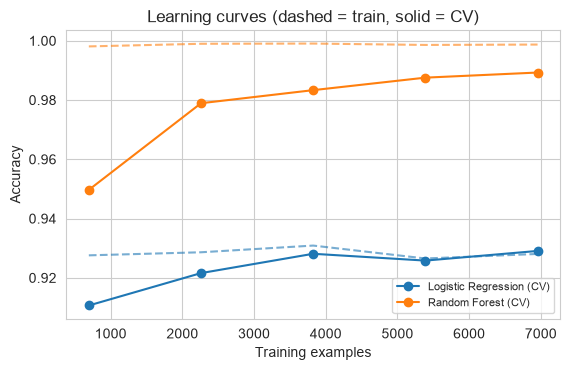

In [19]:
sizes = np.linspace(0.1, 1.0, 5)
plt.figure(figsize=(5.8, 3.8))
for name, factory, color in [("Logistic Regression", make_lr, "tab:blue"),
                             ("Random Forest", make_rf_light, "tab:orange")]:
    ts, tr, va = learning_curve(factory(), Xtr_pca, y_train, train_sizes=sizes,
                                cv=cv3, scoring="accuracy", n_jobs=-1)
    plt.plot(ts, tr.mean(1), "--", color=color, alpha=.6)
    plt.plot(ts, va.mean(1), "-o", color=color, label=f"{name} (CV)")
plt.xlabel("Training examples"); plt.ylabel("Accuracy")
plt.title("Learning curves (dashed = train, solid = CV)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 15. Final evaluation on the held-out test set (PCA representation)

Per-class report, confusion matrices, and one-vs-rest macro ROC-AUC — the appropriate
multiclass metrics.

In [20]:
classes = sorted(np.unique(y))
final = {"Logistic Regression": make_lr().fit(Xtr_pca, y_train),
         "Random Forest": make_rf().fit(Xtr_pca, y_train)}

for name, m in final.items():
    proba = m.predict_proba(Xte_pca)
    yb = label_binarize(y_test, classes=classes)
    auc = roc_auc_score(yb, proba, average="macro", multi_class="ovr")
    print(f"\n===== {name} =====  (one-vs-rest macro ROC-AUC = {auc:.4f})")
    print(classification_report(y_test, m.predict(Xte_pca), digits=3))


===== Logistic Regression =====  (one-vs-rest macro ROC-AUC = 0.9909)
              precision    recall  f1-score   support

Acetaldehyde      0.829     0.820     0.825       484
     Acetone      0.961     0.959     0.960       753
     Ammonia      0.962     0.976     0.969       410
     Ethanol      0.922     0.919     0.920       641
    Ethylene      0.989     0.984     0.986       732
     Toluene      0.841     0.854     0.847       458

    accuracy                          0.926      3478
   macro avg      0.917     0.918     0.918      3478
weighted avg      0.926     0.926     0.926      3478


===== Random Forest =====  (one-vs-rest macro ROC-AUC = 0.9999)
              precision    recall  f1-score   support

Acetaldehyde      0.992     0.990     0.991       484
     Acetone      0.992     0.991     0.991       753
     Ammonia      0.993     0.990     0.991       410
     Ethanol      0.991     0.997     0.994       641
    Ethylene      0.996     0.996     0.996       

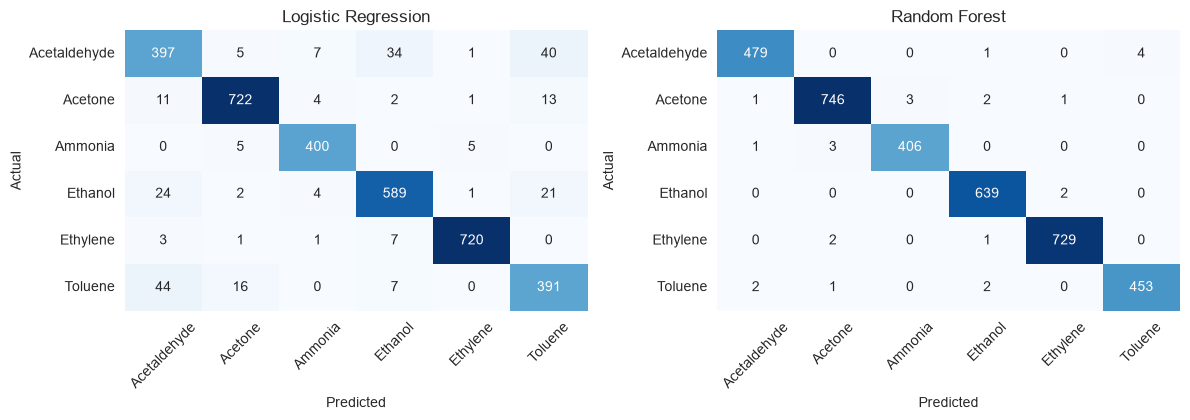

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, (name, m) in zip(axes, final.items()):
    cm = confusion_matrix(y_test, m.predict(Xte_pca), labels=classes)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=classes, yticklabels=classes)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 16. Interpretability - two lenses

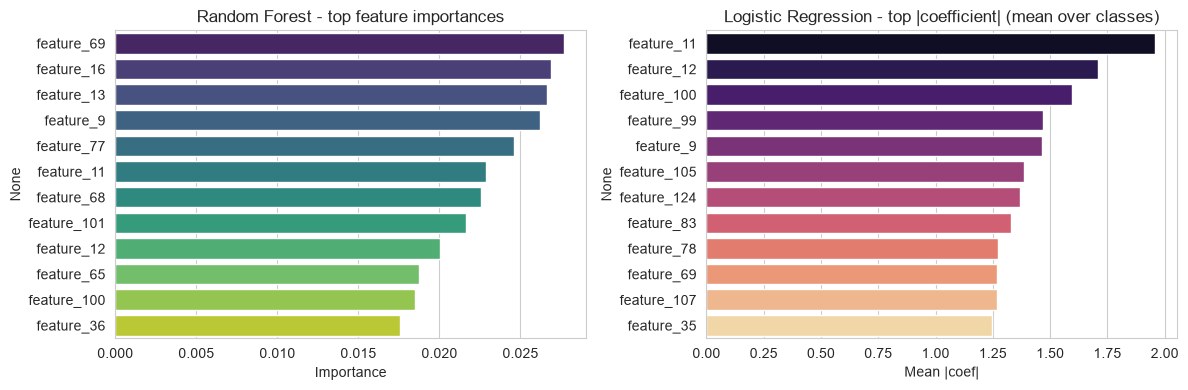

In [22]:
# Random Forest feature importances on the raw 128 features
rf_all = make_rf().fit(X_train_s, y_train)
imp = pd.Series(rf_all.feature_importances_, index=FEATURES).sort_values(ascending=False).head(12)

# Logistic Regression coefficients (mean |coef| across the 6 classes) on raw features
lr_all = make_lr().fit(X_train_s, y_train)
lr_imp = pd.Series(np.abs(lr_all.coef_).mean(axis=0), index=FEATURES).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=imp.values, y=imp.index, palette="viridis", ax=ax[0])
ax[0].set_title("Random Forest - top feature importances"); ax[0].set_xlabel("Importance")
sns.barplot(x=lr_imp.values, y=lr_imp.index, palette="magma", ax=ax[1])
ax[1].set_title("Logistic Regression - top |coefficient| (mean over classes)"); ax[1].set_xlabel("Mean |coef|")
plt.tight_layout(); plt.show()

## 17. The key experiment - performance under sensor drift

A random split mixes all 10 time periods, so train and test share a distribution. In reality
sensors drift. We train on early batches and test on later ones, with scaling and PCA fit on
the **training batches only**, across **three configurations** for robustness.

In [23]:
def drift_eval(train_batches):
    tr = np.isin(batch, train_batches)
    te = ~tr
    sc = StandardScaler().fit(X.values[tr])
    pc = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(sc.transform(X.values[tr]))
    Xtr_d = pc.transform(sc.transform(X.values[tr]))
    Xte_d = pc.transform(sc.transform(X.values[te]))
    row = {}
    for name, factory in [("Logistic Regression", make_lr), ("Random Forest", make_rf)]:
        m = factory().fit(Xtr_d, y[tr])
        row[name] = round(accuracy_score(y[te], m.predict(Xte_d)), 4)
    return row

configs = {"Train 1-5 / test 6-10": [1,2,3,4,5],
           "Train 1-2 / test 3-10": [1,2],
           "Train 1 / test 2-10":   [1]}
drift_df = pd.DataFrame({k: drift_eval(v) for k, v in configs.items()}).T
print("Accuracy on later (unseen) batches:")
display(drift_df)
print("\nFor reference, the random-split accuracy was ~0.99 for both models.")

Accuracy on later (unseen) batches:


,Logistic Regression,Random Forest
Train 1-5 / test 6-10,0.7632,0.6324
Train 1-2 / test 3-10,0.7082,0.6919
Train 1 / test 2-10,0.4596,0.4394



For reference, the random-split accuracy was ~0.99 for both models.


Train-vs-test accuracy gap (evidence of overfitting):
  Logistic Regression    train=0.9129  mean later-batch=0.7043  gap=+0.2086
  Random Forest          train=0.9987  mean later-batch=0.6854  gap=+0.3133


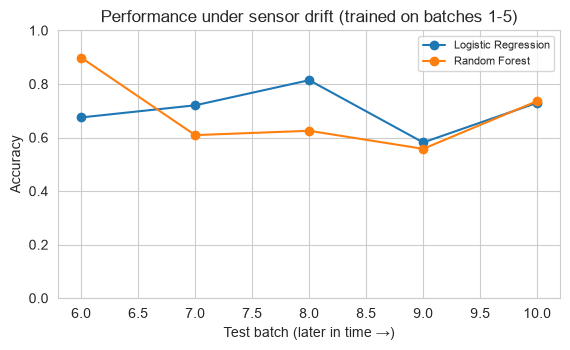

In [24]:
# Per-batch degradation + train-vs-test gap (overfitting evidence), trained on batches 1-5
tr = np.isin(batch, [1,2,3,4,5])
sc = StandardScaler().fit(X.values[tr])
pc = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(sc.transform(X.values[tr]))
Xtr_d = pc.transform(sc.transform(X.values[tr]))
per_batch, gap = {}, {}
fitted = {}
for name, factory in [("Logistic Regression", make_lr), ("Random Forest", make_rf)]:
    m = factory().fit(Xtr_d, y[tr]); fitted[name] = m
    gap[name] = {"Train (batches 1-5)": round(accuracy_score(y[tr], m.predict(Xtr_d)), 4)}
for b in [6,7,8,9,10]:
    mk = batch == b
    Xb = pc.transform(sc.transform(X.values[mk]))
    per_batch[b] = {name: accuracy_score(y[mk], m.predict(Xb)) for name, m in fitted.items()}

print("Train-vs-test accuracy gap (evidence of overfitting):")
for name in fitted:
    tr_acc = gap[name]["Train (batches 1-5)"]
    te_acc = np.mean([per_batch[b][name] for b in [6,7,8,9,10]])
    print(f"  {name:22s} train={tr_acc:.4f}  mean later-batch={te_acc:.4f}  gap={tr_acc-te_acc:+.4f}")

plt.figure(figsize=(5.8, 3.6))
for name in fitted:
    plt.plot([6,7,8,9,10], [per_batch[b][name] for b in [6,7,8,9,10]], marker="o", label=name)
plt.xlabel("Test batch (later in time \u2192)"); plt.ylabel("Accuracy"); plt.ylim(0, 1)
plt.title("Performance under sensor drift (trained on batches 1-5)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()